In [1]:
import plotly.express as px
import pandas as pd
import struct
from glob import glob
from os.path import basename

#plot_order = ["blis", "strassen", "ozimmu_slice_max18", "openblas", "ozimmu_slice_min3", "ozimmu_auto_thresh0", "netlibblas", "ozimmu_auto_thresh8", "ozimmu_auto_thresh1", "cublas", "ozimmu_auto_thresh4", "ozimmu_auto_thresh2"]
plot_order = ["blis", "strassen", "openblas", "ozimmu_auto_thresh0", "netlibblas", "cublas"]
chars = ["A", "B", "C", "D", "E", "F", "G", "H", "I", "J", "K", "L"]
cached_dfs = {}

def summarize_all_componentwise_signed_relative_errors(matrix_type):

    # get paths to all error files
    filepaths = glob(f"results/{matrix_type}/all_componentwise_signed_absolute_errors.*.bin")

    # create a single dataframe for all data
    dfs = []
    reference_values = []
    for filepath in filepaths:
        name = filepath.split(".")[-2]
        if name not in plot_order:
            continue

        if filepath in cached_dfs:
            dfs.append(cached_dfs[filepath])
        else:
            # read in reference values
            if len(reference_values) == 0:
                with open(f"results/{matrix_type}/reference_values.bin", "rb") as f:
                    byte_buffer = f.read()
                    for i in range(0, len(byte_buffer), 8):
                        reference_values.append(struct.unpack('d', byte_buffer[i:i+8]))
                reference_values = pd.DataFrame(reference_values, columns=['reference_values'])    
    
            with open(filepath, "rb") as f:
                byte_buffer = f.read()
    
            signed_absolute_errors = []
            start_byte = 0#8*(32*32)
            end_byte = len(byte_buffer)#8*(32*32 + 64*64)
            for i in range(start_byte,end_byte,8):
                signed_absolute_errors.append(struct.unpack('d', byte_buffer[i:i+8]))
    
            df = pd.DataFrame(signed_absolute_errors, columns=['signed_absolute_errors'])
            df["name"] = name
            df["plot_order"] = f"Figure {chars[plot_order.index(name)]} - {name}"
            df["signed_relative_errors"] = df["signed_absolute_errors"] / reference_values["reference_values"]
            dfs.append(df)

            # save the data
            cached_dfs[filepath] = df

    df = pd.concat(dfs)

    print(f"\n\n============= summary statistics of all signed RELATIVE errors for {matrix_type} matrices =============\n\n")
    for filepath in sorted(filepaths):
        name = filepath.split(".")[-2]
        if name not in plot_order:
            continue
        df_slice = df[df['name'] == name]
        print(f"{name} stats:")
        print(f"\t   mean of signed relative errors: {df_slice['signed_relative_errors'].mean()}")
        print(f"\t    std of signed relative errors: {df_slice['signed_relative_errors'].std()}")

    print(f"\n\n============= histograms of signed RELATIVE errors for {matrix_type} matrices =============\n\n")
    hist = df.hist(column="signed_relative_errors", by='plot_order', figsize=(20,10), bins=120, xrot=0)


def summarize_all_componentwise_signed_absolute_errors(matrix_type):

    # get paths to all error files
    filepaths = glob(f"results/{matrix_type}/all_componentwise_signed_absolute_errors.*.bin")

    # create a single dataframe for all data
    dfs = []
    reference_values = []
    for filepath in filepaths:
        name = filepath.split(".")[-2]
        if name not in plot_order:
            continue

        if filepath in cached_dfs:
            dfs.append(cached_dfs[filepath])
        else:
            if len(reference_values) == 0:
                # read in reference values
                with open(f"results/{matrix_type}/reference_values.bin", "rb") as f:
                    byte_buffer = f.read()
                    for i in range(0, len(byte_buffer), 8):
                        reference_values.append(struct.unpack('d', byte_buffer[i:i+8]))
                reference_values = pd.DataFrame(reference_values, columns=['reference_values'])    
    
            with open(filepath, "rb") as f:
                byte_buffer = f.read()
    
            signed_absolute_errors = []
            start_byte = 0#8*(32*32)
            end_byte = len(byte_buffer)#8*(32*32 + 64*64)
            for i in range(start_byte,end_byte,8):
                signed_absolute_errors.append(struct.unpack('d', byte_buffer[i:i+8]))
    
            df = pd.DataFrame(signed_absolute_errors, columns=['signed_absolute_errors'])
            df["name"] = name
            df["plot_order"] = f"Figure {chars[plot_order.index(name)]} - {name}"
            df["signed_relative_errors"] = df["signed_absolute_errors"] / reference_values["reference_values"]
            dfs.append(df)

            # save the data
            cached_dfs[filepath] = df

    df = pd.concat(dfs)
    print(f"\n\n============= summary statistics of all signed ABSOLUTE errors for {matrix_type} matrices =============\n\n")
    for filepath in sorted(filepaths):
        name = filepath.split(".")[-2]
        if name not in plot_order:
            continue
        df_slice = df[df['name'] == name]
        print(f"{name} stats:")
        print(f"\t   mean of signed absolute errors: {df_slice['signed_absolute_errors'].mean()}")
        print(f"\t    std of signed absolute errors: {df_slice['signed_absolute_errors'].std()}")
        
    print(f"\n\n============= histograms of all signed ABSOLUTE errors for {matrix_type} matrices =============\n\n")
    hist = df.hist(column="signed_absolute_errors", by='plot_order', figsize=(20,10), bins=120, xrot=0)


def plot_max_componentwise_unsigned_relative_errors_vs_dim(matrix_type, log_x=False, log_y=False):

    filepaths = glob(f"results/{matrix_type}/max_componentwise_unsigned_errors.*.txt")
    
    dfs = []
    for filepath in filepaths:
        df = pd.read_csv(filepath)
        name = filepath.split(".")[-2]
        if name not in plot_order:
            continue
        df["name"] = name
        dfs.append(df)
    
    df = pd.concat(dfs, ignore_index=True)

    fig = px.line(
        df,
        x="n",
        y="max_componentwise_unsigned_relative_error",
        markers=True,
        log_x=log_x,
        log_y=log_y,
        title=f"Max Componentwise Unsigned Relative Error vs dim for {matrix_type} matrices",
        hover_data=["m", "n", "k"],
        symbol = "name",
        color="name",
        color_discrete_sequence=px.colors.qualitative.Safe,
    )
    fig.update_traces(
        marker=dict(
            size=20,
            opacity=0.7,
            line_width=2.0,
        )
    )
    fig.update_layout(
        yaxis_tickformat='.2e',
        #xaxis_tickformat='.2e'
        width=1000,
        height=500
    )

    fig.show()

def plot_max_componentwise_unsigned_absolute_errors_vs_dim(matrix_type, log_x=False, log_y=False):

    filepaths = glob(f"results/{matrix_type}/max_componentwise_unsigned_errors.*.txt")
    
    dfs = []
    for filepath in filepaths:
        df = pd.read_csv(filepath)
        name = filepath.split(".")[-2]
        if name not in plot_order:
            continue
        df["name"] = name
        dfs.append(df)
    
    df = pd.concat(dfs, ignore_index=True)

    fig = px.line(
        df,
        x="n",
        y="max_componentwise_unsigned_absolute_error",
        markers=True,
        log_x=log_x,
        log_y=log_y,
        title=f"Max Componentwise Unsigned Absolute Error vs dim for {matrix_type} matrices",
        hover_data=["m", "n", "k"],
        symbol = "name",
        color="name",
        color_discrete_sequence=px.colors.qualitative.Safe,
    )
    fig.update_traces(
        marker=dict(
            size=20,
            opacity=0.7,
            line_width=2.0,
        )
    )
    fig.update_layout(
        yaxis_tickformat='.2e',
        #xaxis_tickformat='.2e'
        width=1000,
        height=500
    )

    fig.show()

def analyze_n_zeros(ratio):
    filepaths = glob(f"results/test1/max_componentwise_abs_errors.*_{ratio}.txt")

    ratio_string = ratio[0] + "." + ratio[1:]
    
    dfs = []
    for filepath in filepaths:
        df = pd.read_csv(filepath)
        df["filename"] = basename(filepath)
        name = filepath.split(".")[-2].split("_")[0]
        df["name"] = name
        dfs.append(df)
    
    df = pd.concat(dfs, ignore_index=True)

    for filepath in filepaths:
        df_slice = df[df['filename'] == basename(filepath)]
        print(f"{filepath}:")
        print(f"\tn_zeros: {df_slice['n_zeros'].sum()}\n")

    df2 = df.copy()

    ref = df[df["filename"] == f"max_componentwise_abs_errors.netlibblas_{ratio}.txt"][["n", "n_zeros"]].rename(columns={"n_zeros": "ref_n_zeros"})

    df2 = df2.merge(ref, on="n", how="left")

    df2["% of zero entries lost"] = (1 - df2["n_zeros"] / df2["ref_n_zeros"]) * 100

    fig = px.box(
        df2[df2["filename"] == f"max_componentwise_abs_errors.strassen_{ratio}.txt"],
        x = "n",
        y = "% of zero entries lost",
        log_x = True,
        title=f"Percentage of zeros lost vs problem dimension (z_ratio = {ratio_string})",
        points = "all",
    )
    
    #fig = px.line(
    #    df2[df2["name"] == "strassen"],
    #    x="n",
    #    y="% of zero entries retained",
    #    markers=True,
    #    title=f"Percentage of zeros retained vs problem dimension",
    #    hover_data=["m", "n", "k"],
        #symbol = "name",
        #symbol="Square?",
        #symbol_sequence=["square", "arrow-wide"],
        #color="name",
        #color_discrete_sequence=px.colors.qualitative.Safe,
    #)
    #fig.update_traces(
    #    marker=dict(
    #        size=20,
    #        opacity=0.7,
    #        line_width=2.0,
    #    )
    #)
    fig.update_layout(
        xaxis_title = "Dimension",
        yaxis_title = "Zeros Retained",
        yaxis_ticksuffix = "%",
        #yaxis_tickformat='.2e',
        #xaxis_tickformat='.2e'
        yaxis_range=[0,100],
        width=1000,
        height=500
    )

    fig = postprocess_figure_for_blog(fig)
    fig.show()

def postprocess_figure_for_blog(fig):

    fig.update_layout(paper_bgcolor='#f8f8f8',
                        font_size=18,
                        font_family="Serif",
                        width=1000,
                        height=500)
    return fig


# Test 1 Matrices: Discriminating Between $O(n^3)$ and Strassen
## Setup
- Problem Sizes: 32, 64, 128, 256, 512, 1024, 2048
- Error Metric: counting total number of zeros in calculated C matrices across all problem sizes
- Tested Implementations:
  1. netlibBLAS
  2. BLIS
  3. OpenBLAS
  4. cuBLAS
  5. OZIMMU with auto slices, mantissa loss threshold of 0 bits
  6. naive 1-level Strassen
## Results, Summarized
Works as expected; see counts below.

In [ ]:
#analyze_n_zeros("025")
#analyze_n_zeros("025-worstcase")

# Test 3 Matrices: Discriminating Between $O(n^3)$+FP and $O(n^3)$+emulation
## Setup
- Problem Sizes: 32, 64, 128, 256, 512, 1024, 2048
- Error Metrics:
  1. All componentwise errors across all problem sizes
  2. Max componentwise error for each problem size
- Tested Implementations:
    1. netlibBLAS
    2. cuBLAS
    3. BLIS
    4. OpenBLAS
    5. Naive 1-level Strassen
    6. OZIMMU with auto slices, mantissa loss threshold of 0 bits
- Input Matrices:
  1. Baseline 1: A,B ~ U(0,1)
  2. Baseline 2: A,B ~ U(-1,1)
  3. Treatment: test3 matrices

## Baseline 1: A,B ~ U(0,1)

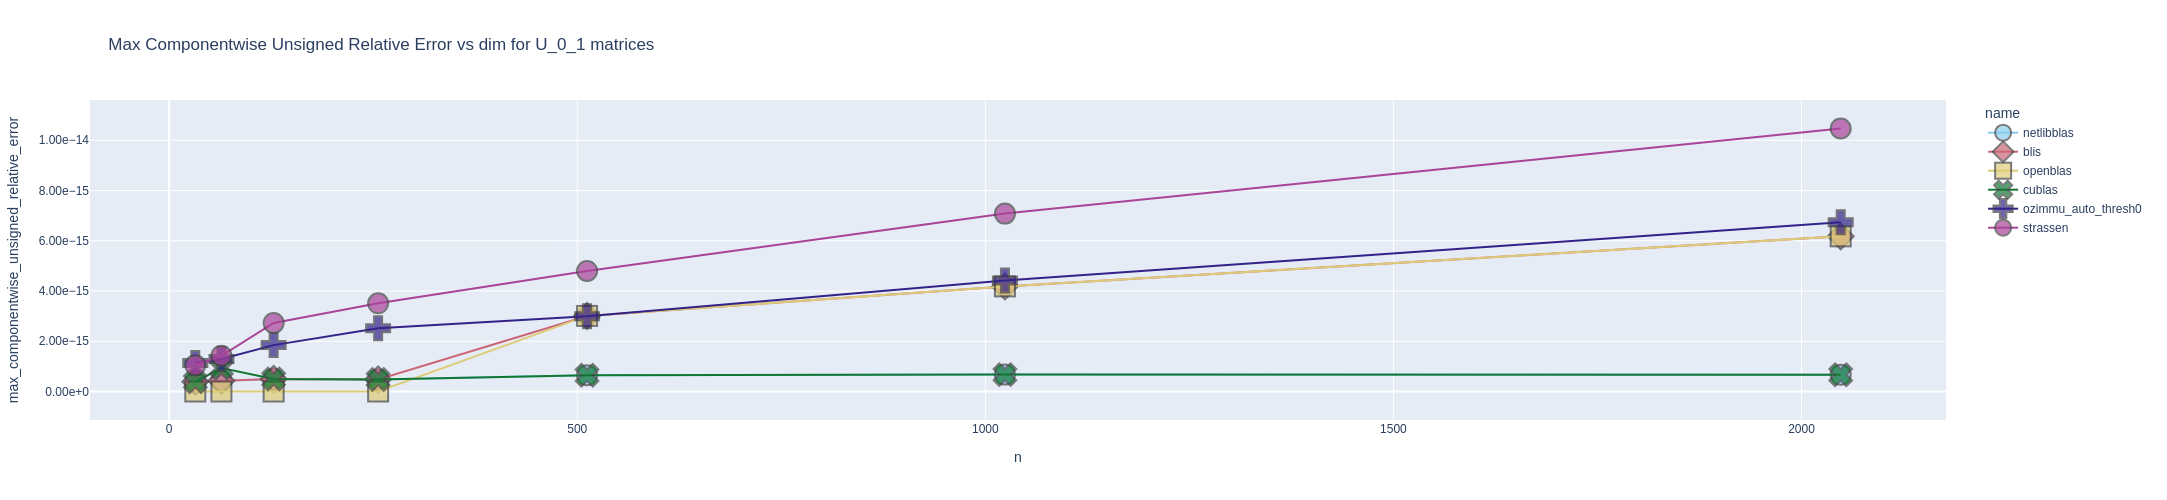

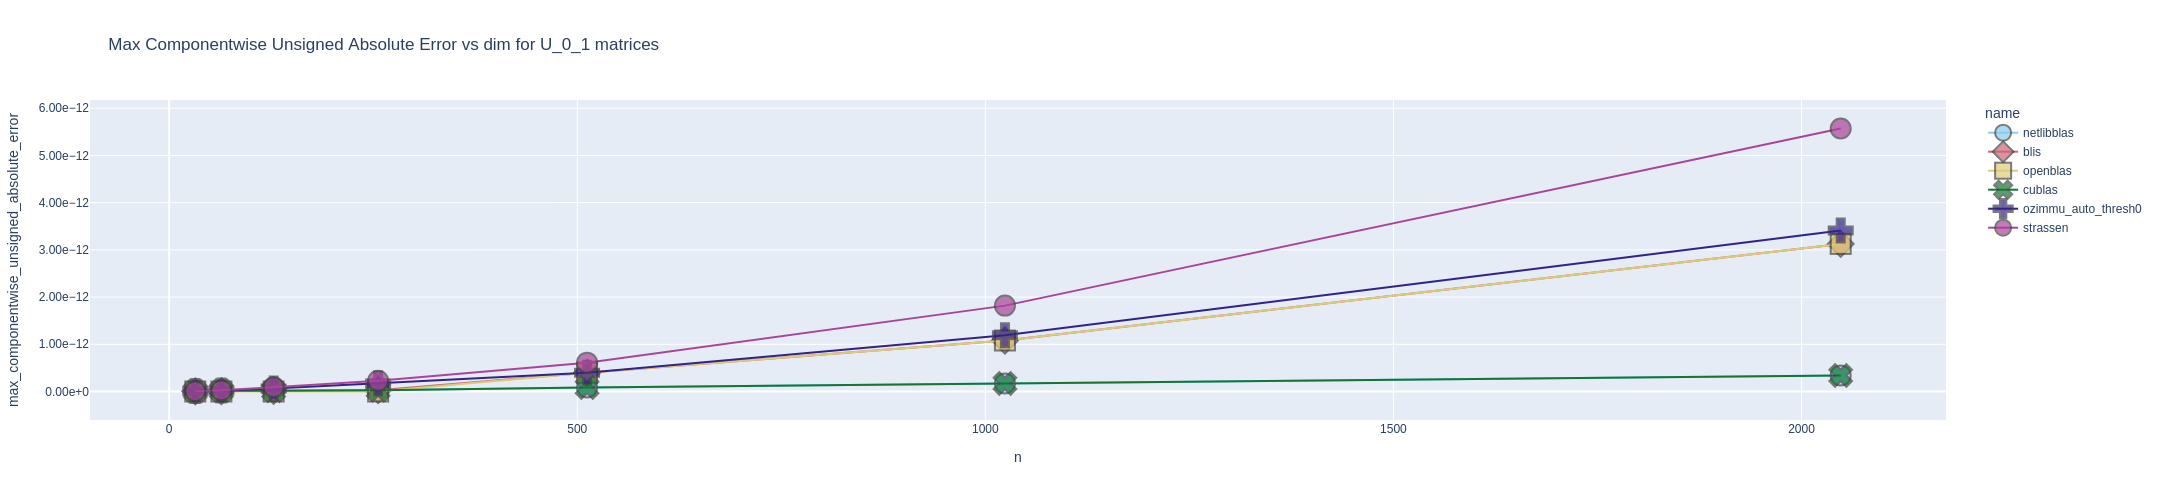

In [3]:
plot_max_componentwise_unsigned_relative_errors_vs_dim("U_0_1")
plot_max_componentwise_unsigned_absolute_errors_vs_dim("U_0_1")



============= summary statistics of all signed RELATIVE errors for U_0_1 matrices =============


blis stats:
	   mean of signed relative errors: 3.920961544181425e-19
	    std of signed relative errors: 1.0560635021747872e-15
cublas stats:
	   mean of signed relative errors: -4.2637809654277703e-20
	    std of signed relative errors: 9.873487117743486e-17
netlibblas stats:
	   mean of signed relative errors: -3.8123333499399635e-20
	    std of signed relative errors: 9.856410712894093e-17
openblas stats:
	   mean of signed relative errors: 3.546799300981311e-19
	    std of signed relative errors: 1.0557414130945826e-15
ozimmu_auto_thresh0 stats:
	   mean of signed relative errors: 3.131296613710635e-16
	    std of signed relative errors: 1.0678793054688431e-15
strassen stats:
	   mean of signed relative errors: 6.499363789859491e-19
	    std of signed relative errors: 1.6427415670026548e-15


============= histograms of signed RELATIVE errors for U_0_1 matrices =============




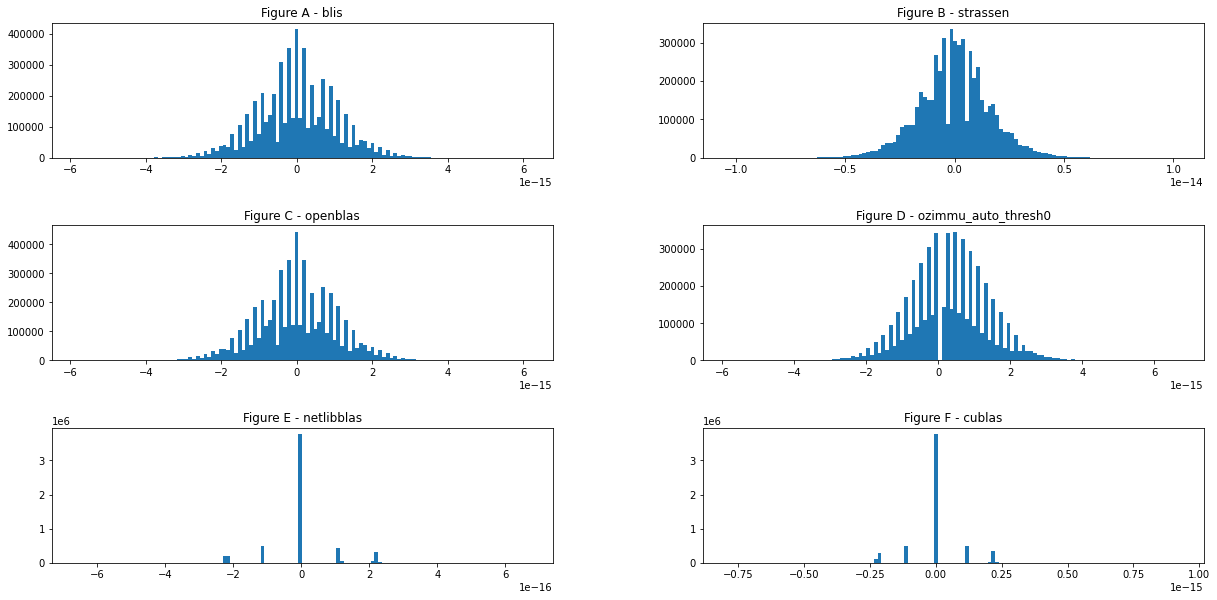

In [6]:
summarize_all_componentwise_signed_relative_errors("U_0_1")



============= summary statistics of all signed ABSOLUTE errors for U_0_1 matrices =============


blis stats:
	   mean of signed absolute errors: 1.8638461773378092e-16
	    std of signed absolute errors: 5.128371198207495e-13
cublas stats:
	   mean of signed absolute errors: -1.023632972928303e-17
	    std of signed absolute errors: 4.5292004250656123e-14
netlibblas stats:
	   mean of signed absolute errors: -1.0166127588980726e-17
	    std of signed absolute errors: 4.529190282276737e-14
openblas stats:
	   mean of signed absolute errors: 1.5273698601228206e-16
	    std of signed absolute errors: 5.127439615128192e-13
ozimmu_auto_thresh0 stats:
	   mean of signed absolute errors: 1.4007464232527803e-13
	    std of signed absolute errors: 5.196144713622722e-13
strassen stats:
	   mean of signed absolute errors: 3.069586996434463e-16
	    std of signed absolute errors: 7.986277256830098e-13


============= histograms of all signed ABSOLUTE errors for U_0_1 matrices =============




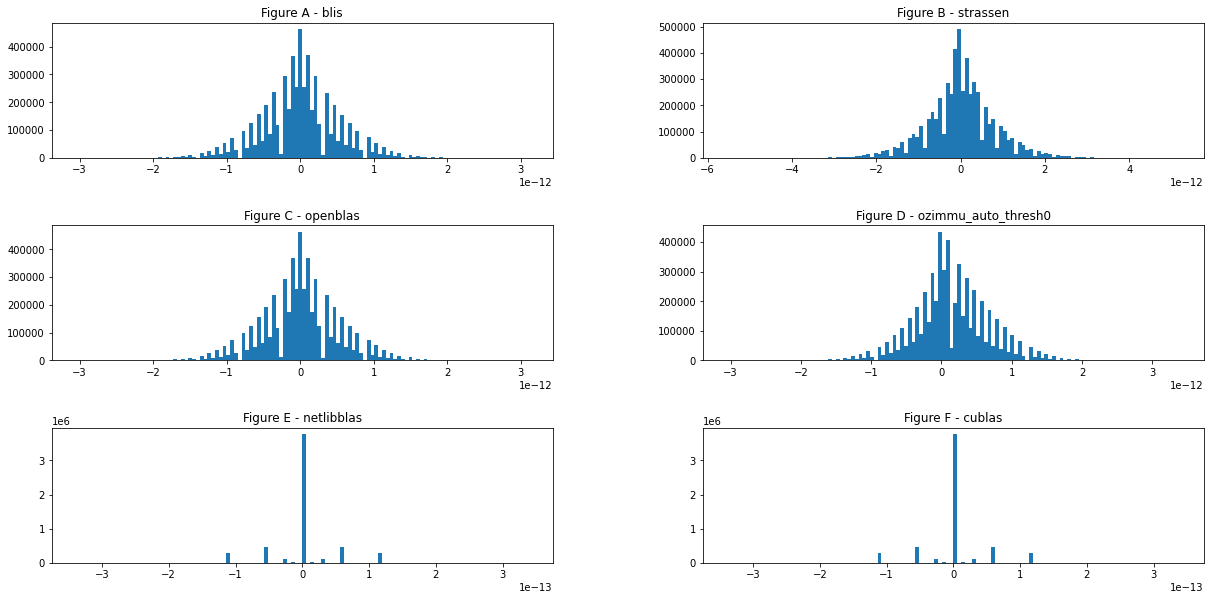

In [7]:
summarize_all_componentwise_signed_absolute_errors("U_0_1")

## Baseline 2: A,B ~ U(-1,1)

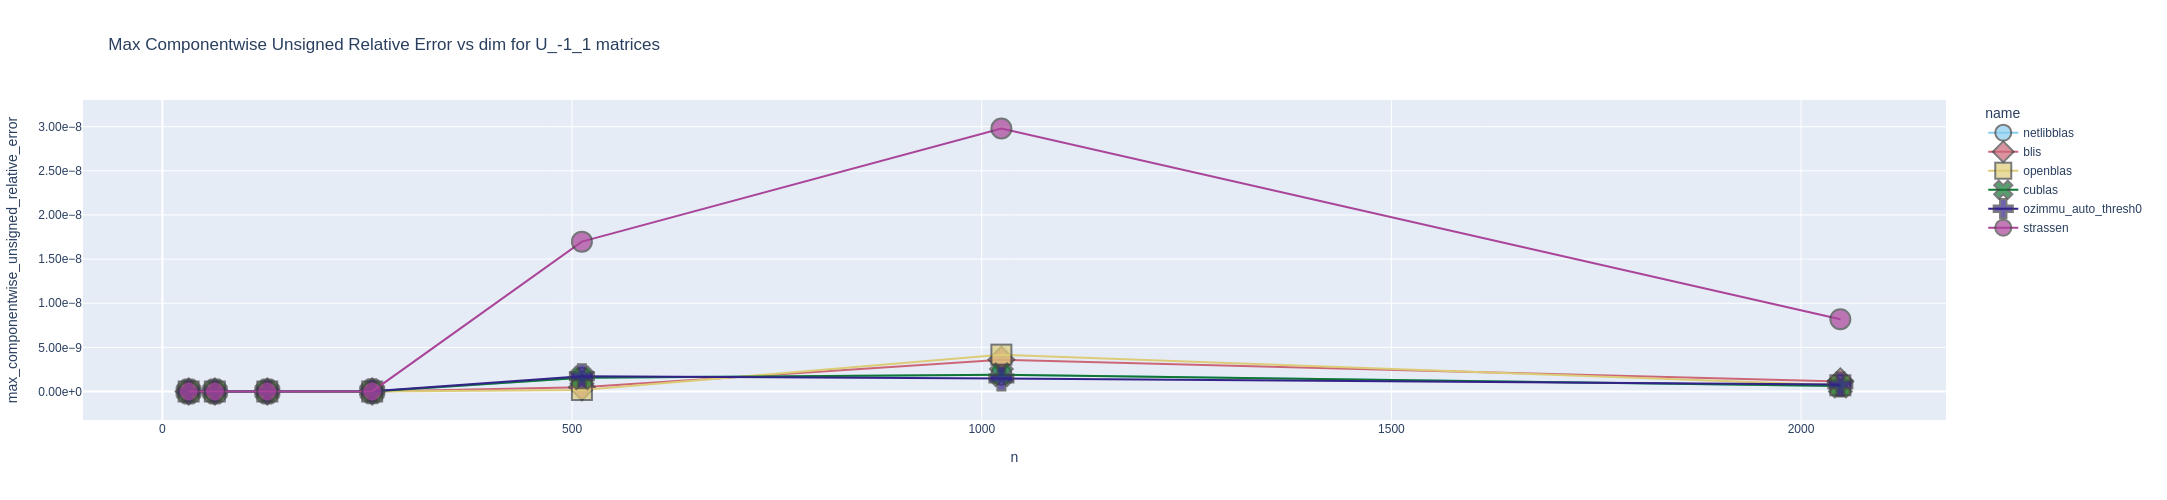

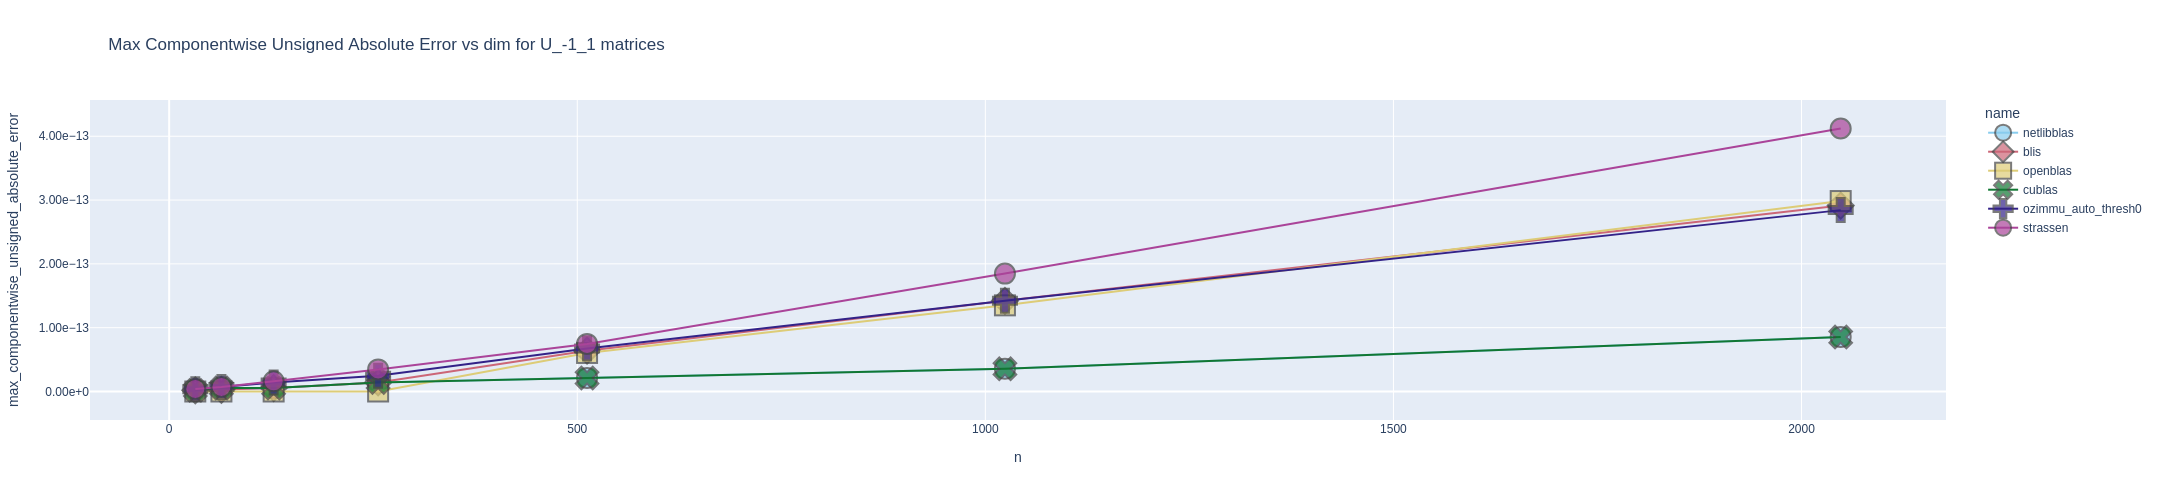

In [4]:
plot_max_componentwise_unsigned_relative_errors_vs_dim("U_-1_1")
plot_max_componentwise_unsigned_absolute_errors_vs_dim("U_-1_1")



============= summary statistics of all signed RELATIVE errors for U_-1_1 matrices =============


blis stats:
	   mean of signed relative errors: 1.053116649284572e-15
	    std of signed relative errors: 1.8184605913299452e-12
cublas stats:
	   mean of signed relative errors: 7.052867427251824e-17
	    std of signed relative errors: 1.125933353279873e-12
netlibblas stats:
	   mean of signed relative errors: 7.055629753210006e-17
	    std of signed relative errors: 1.1259333985960608e-12
openblas stats:
	   mean of signed relative errors: 9.113170003519938e-16
	    std of signed relative errors: 1.9224042947265887e-12
ozimmu_auto_thresh0 stats:
	   mean of signed relative errors: 6.932749140133211e-16
	    std of signed relative errors: 1.2185418940818843e-12
strassen stats:
	   mean of signed relative errors: 1.297755935963191e-15
	    std of signed relative errors: 1.5222025486999467e-11


============= histograms of signed RELATIVE errors for U_-1_1 matrices =============




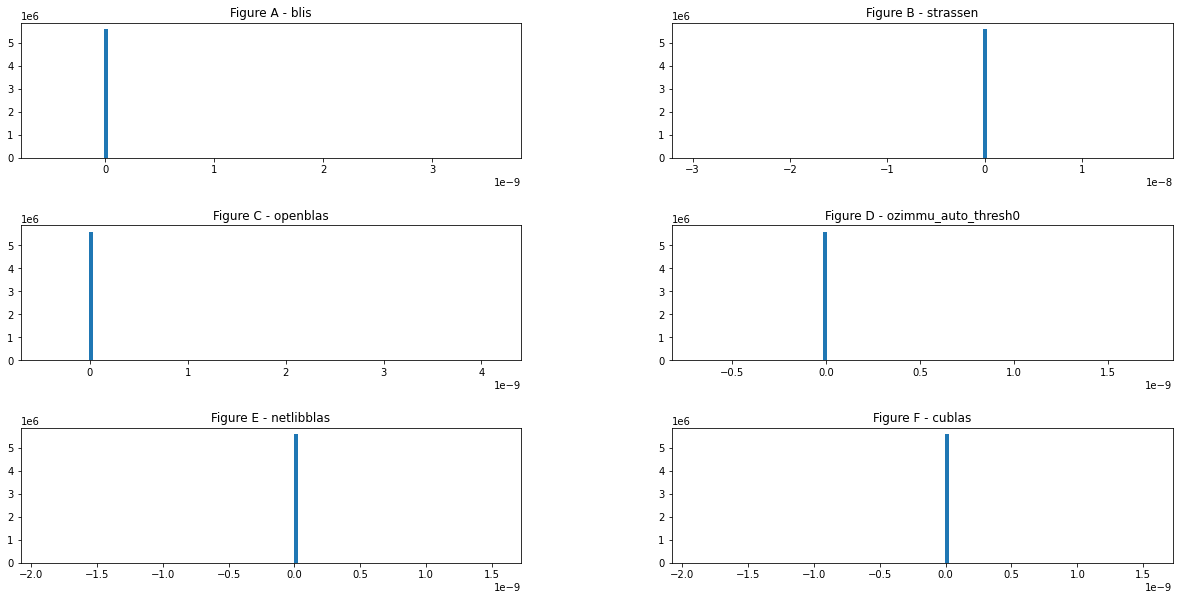

In [8]:
summarize_all_componentwise_signed_relative_errors("U_-1_1")



============= summary statistics of all signed ABSOLUTE errors for U_-1_1 matrices =============


blis stats:
	   mean of signed absolute errors: -4.891970884442301e-18
	    std of signed absolute errors: 2.138456999271398e-14
cublas stats:
	   mean of signed absolute errors: 1.0427187104763797e-18
	    std of signed absolute errors: 6.916193302090876e-15
netlibblas stats:
	   mean of signed absolute errors: 1.0505026384786873e-18
	    std of signed absolute errors: 6.916178484197825e-15
openblas stats:
	   mean of signed absolute errors: -5.989571103522496e-18
	    std of signed absolute errors: 2.1304431972294494e-14
ozimmu_auto_thresh0 stats:
	   mean of signed absolute errors: -8.655546772152356e-18
	    std of signed absolute errors: 2.0685195314314075e-14
strassen stats:
	   mean of signed absolute errors: 4.0384071722122447e-19
	    std of signed absolute errors: 3.5403778351931676e-14


============= histograms of all signed ABSOLUTE errors for U_-1_1 matrices =============


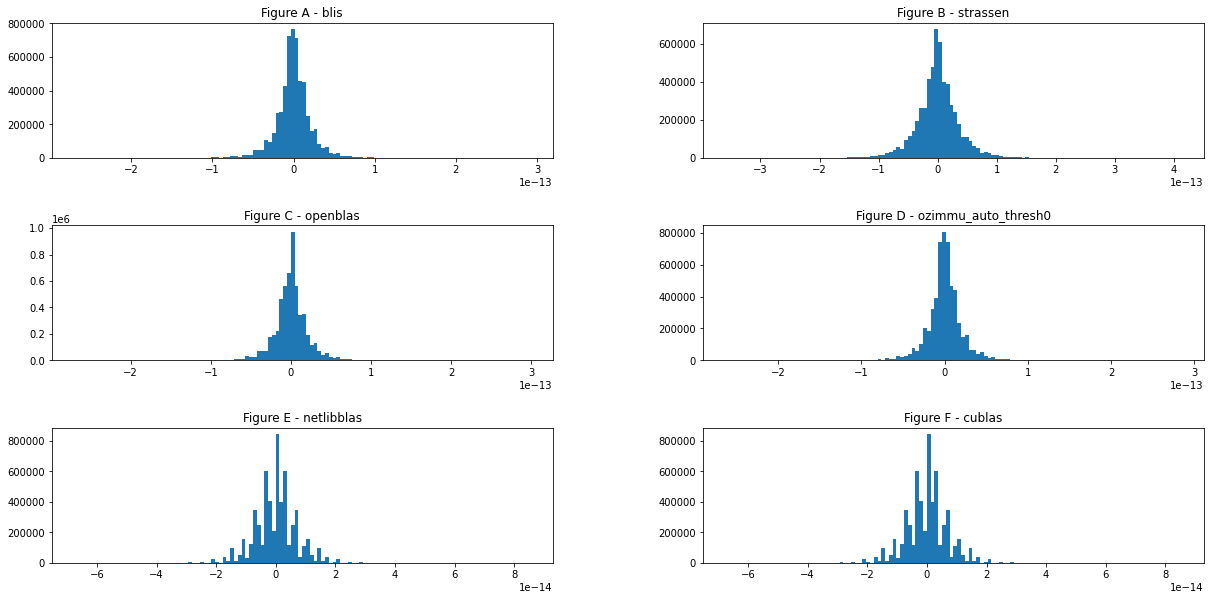

In [9]:
summarize_all_componentwise_signed_absolute_errors("U_-1_1")

## Treatment: Test3 Matrices

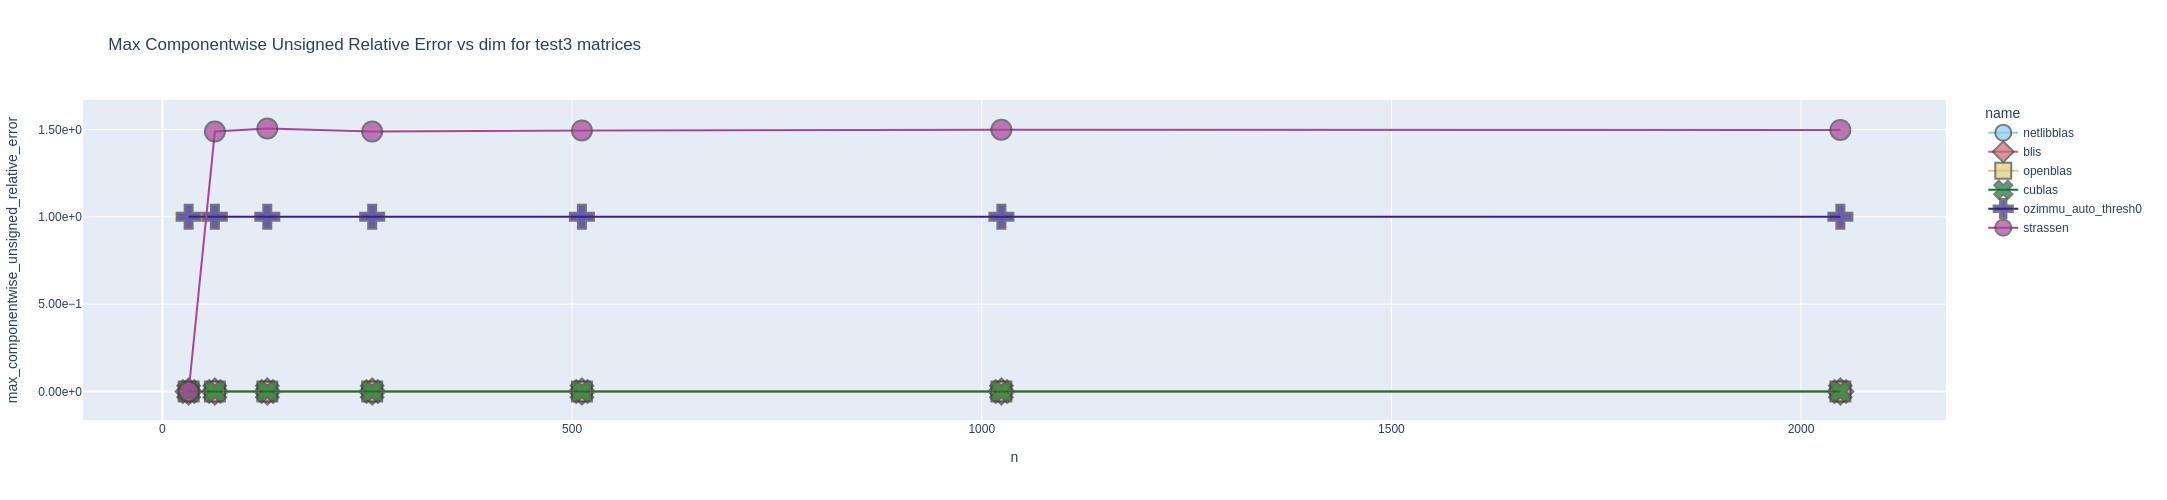

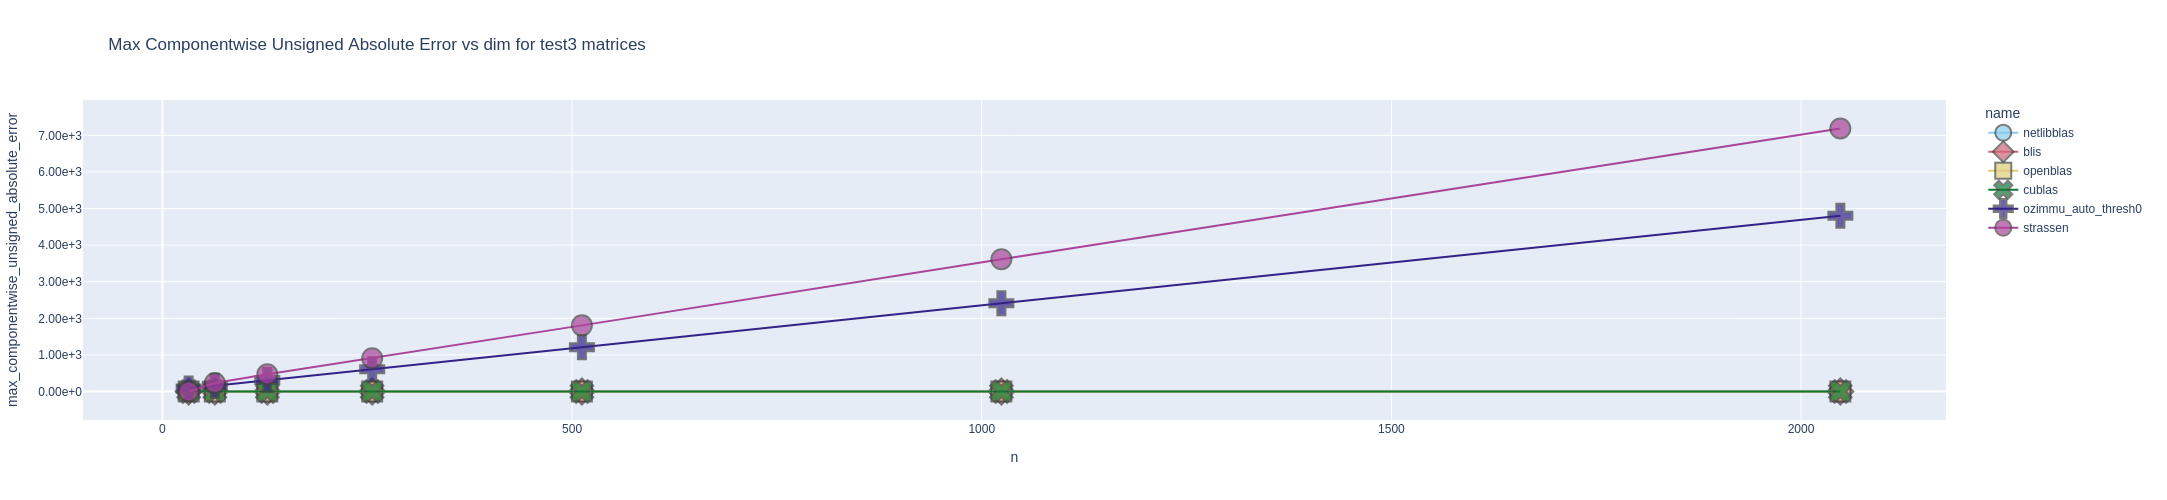

In [5]:
plot_max_componentwise_unsigned_relative_errors_vs_dim("test3")
plot_max_componentwise_unsigned_absolute_errors_vs_dim("test3")



============= summary statistics of all signed RELATIVE errors for test3 matrices =============


blis stats:
	   mean of signed relative errors: 1.473498348507108e-15
	    std of signed relative errors: 5.065614515448539e-16
cublas stats:
	   mean of signed relative errors: -1.677068149907365e-19
	    std of signed relative errors: 5.540146029992353e-18
netlibblas stats:
	   mean of signed relative errors: -3.292607963555715e-20
	    std of signed relative errors: 2.4329679304578166e-18
openblas stats:
	   mean of signed relative errors: 1.5176887820400324e-15
	    std of signed relative errors: 4.539172891879389e-16
ozimmu_auto_thresh0 stats:
	   mean of signed relative errors: 1.0
	    std of signed relative errors: 0.0
strassen stats:
	   mean of signed relative errors: 0.7486675494799256
	    std of signed relative errors: 0.558448760246138


============= histograms of signed RELATIVE errors for test3 matrices =============




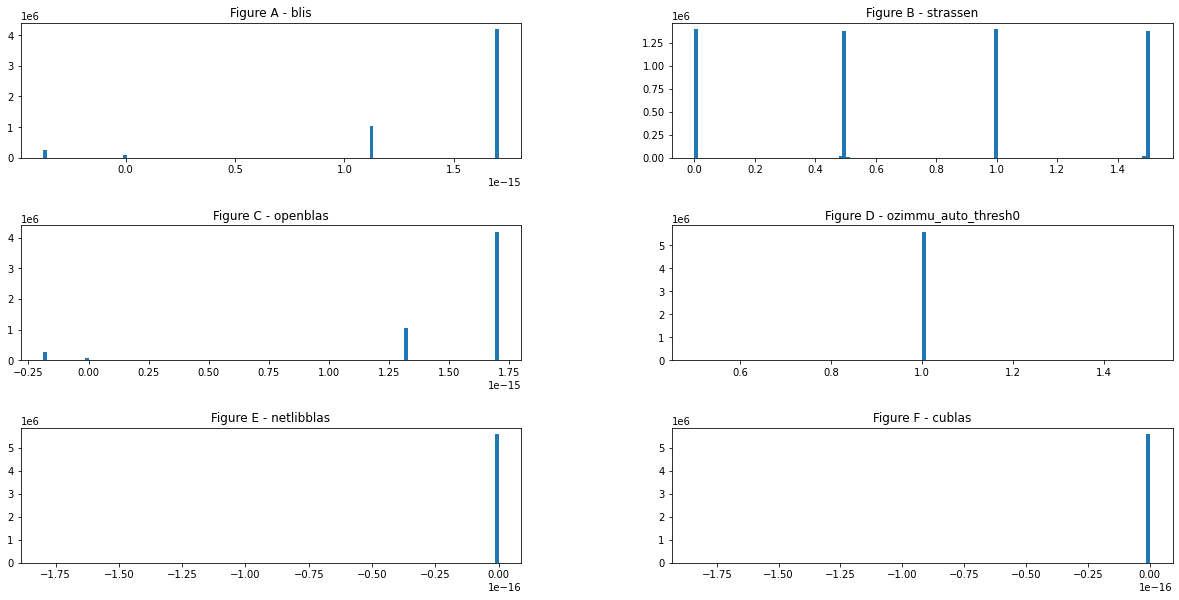

In [10]:
summarize_all_componentwise_signed_relative_errors("test3")



============= summary statistics of all signed ABSOLUTE errors for test3 matrices =============


blis stats:
	   mean of signed absolute errors: 6.629765771346276e-12
	    std of signed absolute errors: 2.7759941144515623e-12
cublas stats:
	   mean of signed absolute errors: -2.3420196381032417e-17
	    std of signed absolute errors: 7.925361260215833e-16
netlibblas stats:
	   mean of signed absolute errors: -2.6022440423369353e-18
	    std of signed absolute errors: 1.9228454684879765e-16
openblas stats:
	   mean of signed absolute errors: 6.725697497967027e-12
	    std of signed absolute errors: 2.6309226256846993e-12
ozimmu_auto_thresh0 stats:
	   mean of signed absolute errors: 4117.365711434866
	    std of signed absolute errors: 1221.3356984679417
strassen stats:
	   mean of signed absolute errors: 3083.182868809833
	    std of signed absolute errors: 2566.575102048221


============= histograms of all signed ABSOLUTE errors for test3 matrices =============




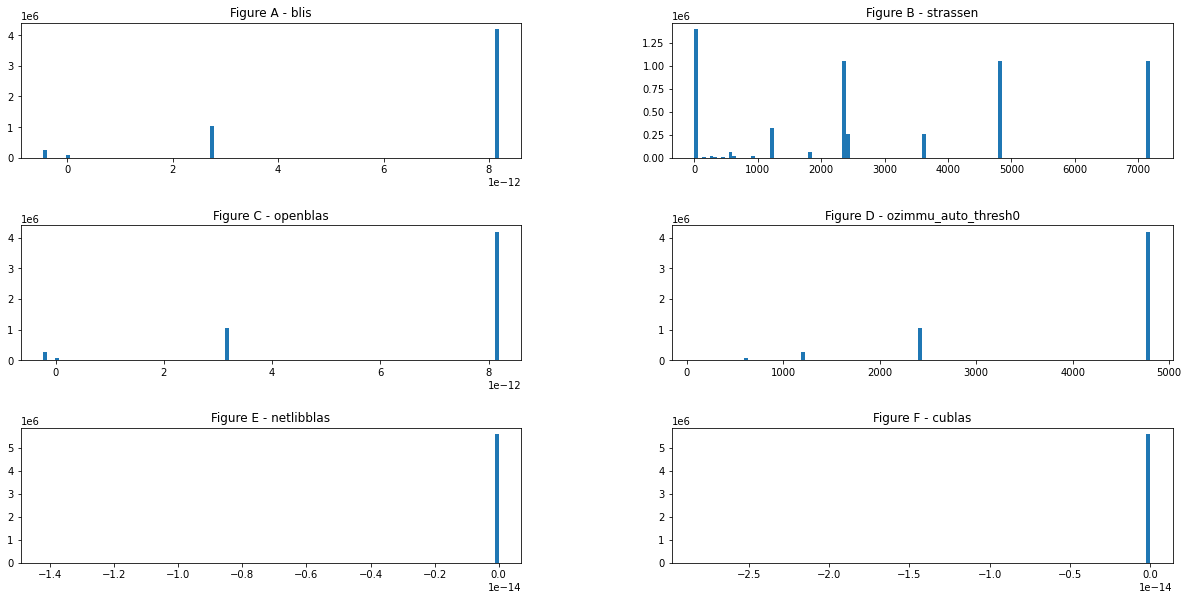

In [11]:
summarize_all_componentwise_signed_absolute_errors("test3")